In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.ensemble import IsolationForest

In [2]:
file_path = "CH2O_09337_DFRS_DS95_2021_272_00_57/calibrated/ch2o_frs_calibrated_01_21272001904.csv"

df = pd.read_csv(file_path, header=None)

df.columns = [
    "Day",
    "Time",
    "Frequency",
    "Value_1",
    "Value_2",
    "Signal"
]

df.head()

,Day,Time,Frequency,Value_1,Value_2,Signal
0,2021-272,1144.00000,2.240000e+09,2.239989e+09,2.239989e+09,17.477752
1,2021-272,1144.08192,2.240000e+09,2.239989e+09,2.239989e+09,17.492057
2,2021-272,1144.16384,2.240000e+09,2.239989e+09,2.239989e+09,17.385770
3,2021-272,1144.24576,2.240000e+09,2.239989e+09,2.239989e+09,17.296193
4,2021-272,1144.32768,2.240000e+09,2.239989e+09,2.239989e+09,17.574878


In [3]:
features = df[["Signal"]]
features.head()

,Signal
0,17.477752
1,17.492057
2,17.385770
3,17.296193
4,17.574878


In [4]:
model = IsolationForest(
    contamination=0.05,
    random_state=42
)

model.fit(features)

,n_estimators,100
,max_samples,'auto'
,contamination,0.05
,max_features,1.0
,bootstrap,False
,n_jobs,None
,random_state,42
,verbose,0
,warm_start,False


In [5]:
df["Anomaly"] = model.predict(features)

df.head()

,Day,Time,Frequency,Value_1,Value_2,Signal,Anomaly
0,2021-272,1144.00000,2.240000e+09,2.239989e+09,2.239989e+09,17.477752,1
1,2021-272,1144.08192,2.240000e+09,2.239989e+09,2.239989e+09,17.492057,1
2,2021-272,1144.16384,2.240000e+09,2.239989e+09,2.239989e+09,17.385770,1
3,2021-272,1144.24576,2.240000e+09,2.239989e+09,2.239989e+09,17.296193,1
4,2021-272,1144.32768,2.240000e+09,2.239989e+09,2.239989e+09,17.574878,1


In [6]:
ice_regions = df[df["Anomaly"] == -1]

print("Potential Ice Regions:")
print(len(ice_regions))

Potential Ice Regions:
623


In [7]:
ice_regions.head(20)

,Day,Time,Frequency,Value_1,Value_2,Signal,Anomaly
122,2021-272,1153.994240,2.240000e+09,2.240200e+09,2.239989e+09,210683.615156,-1
123,2021-272,1154.076160,2.240000e+09,2.240200e+09,2.239989e+09,210684.007046,-1
124,2021-272,1154.158080,2.240000e+09,2.240200e+09,2.239989e+09,210684.384929,-1
125,2021-272,1154.240000,2.240000e+09,2.240200e+09,2.239989e+09,210684.754993,-1
126,2021-272,1154.321920,2.240000e+09,2.240200e+09,2.239989e+09,210685.093604,-1
127,2021-272,1154.403840,2.240000e+09,2.240200e+09,2.239989e+09,210685.498058,-1
128,2021-272,1154.485760,2.240000e+09,2.240200e+09,2.239989e+09,210685.851332,-1
129,2021-272,1154.567680,2.240000e+09,2.240200e+09,2.239989e+09,210686.226171,-1
130,2021-272,1154.649600,2.240000e+09,2.240200e+09,2.239989e+09,210686.597672,-1
131,2021-272,1154.731520,2.240000e+09,2.240200e+09,2.239989e+09,210686.958755,-1


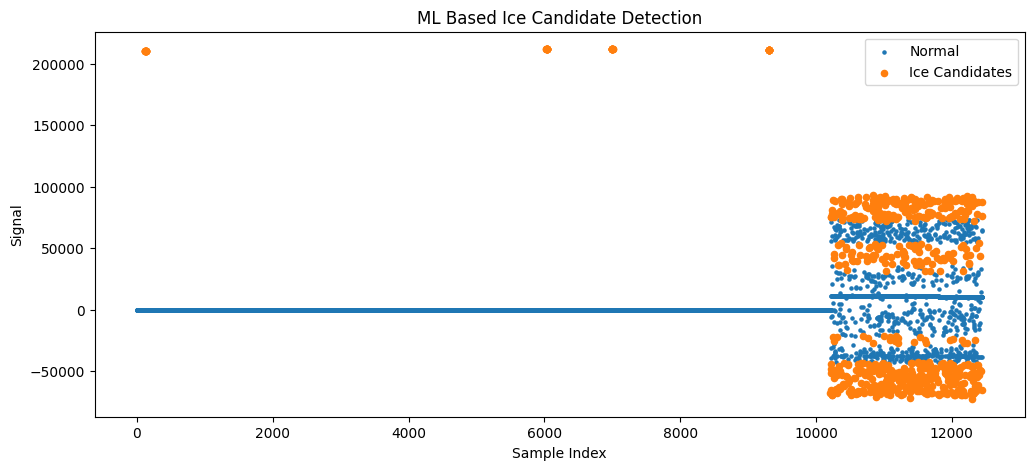

In [8]:
plt.figure(figsize=(12,5))

plt.scatter(
    df.index,
    df["Signal"],
    s=5,
    label="Normal"
)

plt.scatter(
    ice_regions.index,
    ice_regions["Signal"],
    s=20,
    label="Ice Candidates"
)

plt.title("ML Based Ice Candidate Detection")
plt.xlabel("Sample Index")
plt.ylabel("Signal")

plt.legend()

plt.show()

In [9]:
ice_regions.to_csv(
    "ml_detected_ice_regions.csv",
    index=False
)

print("Saved Successfully")

Saved Successfully
